# Spatiotemporal Resource Allocation and Hardware Overhead in Photonic Architectures

A numerical study of temporal-mode multiplexing, optical loss, sequential emission, and resource throughput, followed by a finite-capacity, event-driven scheduling model.

The analysis uses explicit probabilistic assumptions and compares analytical expressions with seeded Monte Carlo simulations. **The output metrics describe accepted resource-preparation events, not graph-state fidelity, computational advantage, or fault-tolerant logical throughput.**

**Contents**

1. Physical architecture and timing
2. Sequential-emitter reference model
3. Delay-line and switching attenuation
4. Temporal multiplexing under latest-arrival selection
5. An optional two-mode beam-splitter example
6. Monte Carlo validation and resource overhead
7. Rate–resource Pareto and hardware-sensitivity analysis
8. Reproducible resource sweep
9. Finite-buffer online scheduling: first-arrival selection, analytical baseline, and validation

The entire numerical implementation is included below; no local Python module is required. NumPy and Matplotlib are required; Perceval is optional.

## Numerical model

The following definitions implement the analytical survival model, source/measurement bookkeeping, Monte Carlo estimator, and Pareto filtering used throughout Sections 1–8. Keeping these functions in the notebook makes the computational results reproducible without a separate package.

In [1]:
from dataclasses import dataclass, replace
import math
import numpy as np

@dataclass(frozen=True)
class Hardware:
    source_prob: float = 0.55
    transmission: float = 0.90
    detector_eff: float = 0.92
    switch_eff: float = 0.985
    delay_eff_per_bin: float = 0.97
    fusion_prob: float = 0.5
    period_ns: float = 10.0

    def __post_init__(self):
        for name in ('source_prob','transmission','detector_eff','switch_eff','delay_eff_per_bin','fusion_prob'):
            v = getattr(self,name)
            if not (0 <= v <= 1):
                raise ValueError(f'{name} must be in [0,1]')
        if self.period_ns <= 0:
            raise ValueError('period_ns must be positive')

@dataclass(frozen=True)
class Architecture:
    rails: int = 3
    bins: int = 4
    fusions: int = 2
    def __post_init__(self):
        if not isinstance(self.rails,int) or self.rails < 1: raise ValueError('rails must be positive integer')
        if not isinstance(self.bins,int) or self.bins < 1: raise ValueError('bins must be positive integer')
        if not isinstance(self.fusions,int) or self.fusions < 0: raise ValueError('fusions must be nonnegative integer')

def switch_depth(bins):
    if bins < 1: raise ValueError('bins must be positive')
    return math.ceil(math.log2(bins))

def photon_availability(h):
    return h.source_prob*h.transmission*h.detector_eff

def per_rail_acceptance(a,h):
    """Exact acceptance for latest *available* emission in the window."""
    p=photon_availability(h)
    switch=h.switch_eff**switch_depth(a.bins)
    r=(1-p)*h.delay_eff_per_bin
    return switch*p*sum(r**age for age in range(a.bins))

def analytical_metrics(a,h):
    rail=per_rail_acceptance(a,h)
    success=rail**a.rails*h.fusion_prob**a.fusions
    window_s=a.bins*h.period_ns*1e-9
    return {
        'rail_acceptance':rail,
        'success_probability':success,
        'attempts_per_window':a.rails*a.bins,
        'switch_depth':switch_depth(a.bins),
        'window_s':window_s,
        'throughput_hz':success/window_s,
        'attempts_per_output':a.rails*a.bins/success if success>0 else math.inf,
    }

def monte_carlo(a,h,shots=100_000,seed=42):
    if not isinstance(shots,int) or shots<=0: raise ValueError('shots must be positive integer')
    rng=np.random.default_rng(seed)
    p=photon_availability(h)
    available=rng.random((shots,a.rails,a.bins))<p
    any_available=np.any(available,axis=2)
    # latest index, taking -1 when none available
    latest=np.where(any_available,a.bins-1-np.argmax(available[:,:,::-1],axis=2),-1)
    age=np.where(any_available,a.bins-1-latest,0)
    delay_survives=rng.random((shots,a.rails)) < h.delay_eff_per_bin**age
    switch_survives=rng.random((shots,a.rails)) < h.switch_eff**switch_depth(a.bins)
    rails_ok=np.all(any_available & delay_survives & switch_survives,axis=1)
    fusions_ok=np.all(rng.random((shots,a.fusions))<h.fusion_prob,axis=1)
    output=rails_ok & fusions_ok
    successes=int(output.sum())
    success=successes/shots
    return {
      'success_probability':success,
      'standard_error':math.sqrt(success*(1-success)/shots),
      'successes':successes,
      'shots':shots,
      'throughput_hz':success/(a.bins*h.period_ns*1e-9),
      'attempts_per_output':a.rails*a.bins/success if success else math.inf,
      'mean_selected_storage_bins':float(age[any_available].mean()) if np.any(any_available) else math.nan,
    }

def sweep_bins(h,rails=3,fusions=2,bins=range(1,17)):
    return [{ 'bins':m, **analytical_metrics(Architecture(rails,m,fusions),h)} for m in bins]

def pareto_front(rows, cost_key='attempts_per_output', benefit_key='throughput_hz'):
    """Returns non-dominated rows, minimize cost and maximize benefit."""
    front=[]
    for row in rows:
        dominated=any(
            other is not row and other[cost_key] <= row[cost_key] and
            other[benefit_key]>=row[benefit_key] and
            (other[cost_key]<row[cost_key] or other[benefit_key]>row[benefit_key])
            for other in rows)
        if not dominated: front.append(row)
    return front

def sequential_emitter_reference(photons,p_emit,transmission,detector_eff,cycle_ns,T2_ns):
    """Illustrative spin-assisted source; coherence proxy is NOT graph fidelity."""
    if photons<1 or cycle_ns<=0 or T2_ns<=0: raise ValueError('invalid parameters')
    if any(not 0<=v<=1 for v in (p_emit,transmission,detector_eff)): raise ValueError('invalid efficiencies')
    p=(p_emit*transmission*detector_eff)**photons
    visibility=math.exp(-(photons-1)*cycle_ns/T2_ns)
    return {'success_probability':p,'output_rate_hz':p/(photons*cycle_ns*1e-9),
            'spin_coherence_proxy':visibility}

In [2]:
import matplotlib.pyplot as plt
from pathlib import Path

FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)
RESULTS = Path("results")
RESULTS.mkdir(exist_ok=True)
print("Libraries loaded")

Libraries loaded


## Part 1 — Physical architecture and timing

A **time bin** is a discrete emission opportunity separated by the source clock period $T$. We consider $k$ independently supplied input rails, with $m$ opportunities per rail before a shared deadline. The output can be accepted only when every rail supplies one available photon and $f$ required heralded fusion events succeed.

**Physical caution:** In real photonic graph-state generation, the required optical network, fusion outcomes, component timing, and feed-forward differ by protocol. Here we compare explicitly declared scheduling assumptions rather than extrapolating a universal law.

In [3]:
h = Hardware(); a = Architecture(rails=3,bins=4,fusions=2)
print(h)
print(a)
print('Input availability per pulse:', photon_availability(h))
print('Window length (ns):', a.bins*h.period_ns)
print('Required switching stages:', switch_depth(a.bins))

Hardware(source_prob=0.55, transmission=0.9, detector_eff=0.92, switch_eff=0.985, delay_eff_per_bin=0.97, fusion_prob=0.5, period_ns=10.0)
Architecture(rails=3, bins=4, fusions=2)
Input availability per pulse: 0.4554000000000001
Window length (ns): 40.0
Required switching stages: 2


### Bin schedule and optical storage age

For a candidate emitted at bin $j\in\{0,\ldots,m-1\}$, an output synchronized to the final bin requires storage age
$$d=m-1-j.$$
The optical delay is $\tau=dT$. In a waveguide/fibre loss model with attenuation $\alpha_{\rm dB}$ per time bin, the transmission factor is $10^{-\alpha_{\rm dB}d/10}$, which is equivalent to $\eta_{\rm delay}^{d}$ with $\eta_{\rm delay}=10^{-\alpha_{\rm dB}/10}$.

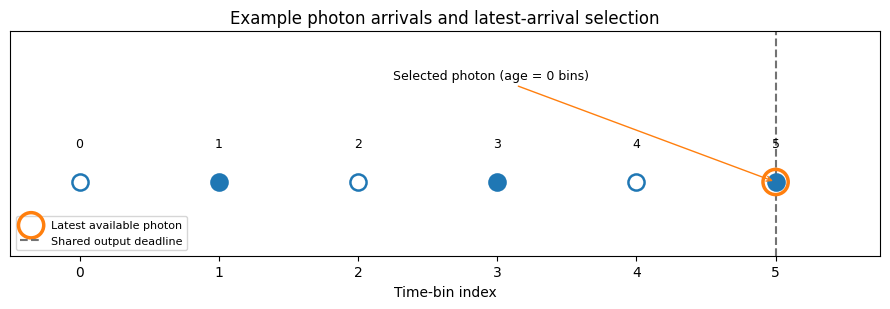

In [4]:
# One illustrative sequence of heralded candidate arrivals (not a stochastic measurement).
arrivals_example = [False, True, False, True, False, True]
m = len(arrivals_example)
selected_bin = max(j for j, arrived in enumerate(arrivals_example) if arrived)

fig, ax = plt.subplots(figsize=(9, 3.2))
for j, arrived in enumerate(arrivals_example):
    ax.scatter(j, 1, s=135, facecolor="tab:blue" if arrived else "white",
               edgecolor="tab:blue", linewidth=1.8, zorder=3)
    ax.text(j, 1.11, str(j), ha="center", fontsize=9)

ax.scatter(selected_bin, 1, s=330, facecolors="none", edgecolors="tab:orange",
           linewidths=2.5, label="Latest available photon", zorder=4)
ax.annotate("Selected photon (age = 0 bins)", xy=(selected_bin, 1),
            xytext=(2.25, 1.32), arrowprops={"arrowstyle": "->", "color": "tab:orange"},
            fontsize=9)
ax.axvline(m - 1, linestyle="--", color="0.45", label="Shared output deadline")
ax.set(xlim=(-0.5, m - 0.25), ylim=(0.77, 1.47), xlabel="Time-bin index",
       yticks=[], title="Example photon arrivals and latest-arrival selection")
ax.legend(loc="lower left", fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / "timing_bins.png", dpi=160)
plt.show()

## Part 2 — Sequential quantum-dot emission and spin memory

For a spin-assisted emitter that produces a sequence of $k$ photons, each cycle takes time $T$. The simplest independent emission/delivery model predicts
$$P_{\rm src}=(p_{\rm emit}\eta_{\rm tx}\eta_{\rm det})^k.$$
A separate phenomenological spin-coherence *proxy* may be $V_{\rm spin}=\exp[-(k-1)T/T_2]$. This is **not** the resulting photonic graph-state fidelity; deriving fidelity requires specifying the spin-photon gates, measurement and noise channels.

In [5]:
for k in [2,4,8,16]:
    result=sequential_emitter_reference(k,.93,.95,.95,10,100)
    print(f"k={k:2d}, availability={result['success_probability']:.5f}, "
          f"coherence proxy={result['spin_coherence_proxy']:.4f}")

k= 2, availability=0.70447, coherence proxy=0.9048
k= 4, availability=0.49627, coherence proxy=0.7408
k= 8, availability=0.24629, coherence proxy=0.4966
k=16, availability=0.06066, coherence proxy=0.2231


## Part 3 — Delay lines, switches and physical attenuation

Let $p_0=\eta_{\rm src}\eta_{\rm tx}\eta_{\rm det}$ be the probability that a photon is initially available in one time bin. If a binary switching network has $d_s=\lceil\log_2m\rceil$ stages, each with intensity transmission $\eta_s$, selected-photon switch survival is $\eta_s^{d_s}$. A photon stored for $a$ bins survives delay with probability $\eta_d^a$.

A model with switch depth $\lceil\log_2m\rceil$ is an assumption about a specific switching-network organization. It is not a universal minimum hardware count.

**Preselection convention:** The factor $\eta_{\mathrm{det}}$ is included in $p_0$ only if detection or heralding determines *availability before selection* (e.g., an independently heralded source). For an output-only destructive detector, its efficiency should instead multiply the survival probability **after** selection. The simplified input model uses the former convention; no claim is made that every quantum-dot system provides preselection heralding.

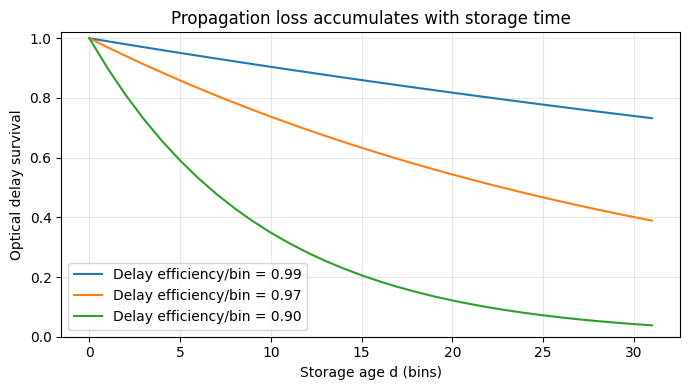

In [6]:
ages = np.arange(0, 32)
fig, ax = plt.subplots(figsize=(7, 4))
for eta_d in [0.99, 0.97, 0.90]:
    ax.plot(ages, eta_d**ages, label=f"Delay efficiency/bin = {eta_d:.2f}")
ax.set(xlabel="Storage age d (bins)", ylabel="Optical delay survival",
       title="Propagation loss accumulates with storage time", ylim=(0, 1.02))
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURES / "delay_loss.png", dpi=160)
plt.show()

## Part 4 — Temporal multiplexing and exact rail acceptance

Our selection rule chooses the **latest initially available** photon in a window. Earlier successes are discarded, and the selected candidate is subsequently subject to storage and switch losses. The probability that the latest available photon has age $a$ is
$$P(A=a)=p_0(1-p_0)^a, \qquad a=0,\ldots,m-1.$$
This is an *unconditional* probability; the all-unavailable event has weight $(1-p_0)^m$.

Therefore, the probability that a rail supplies an accepted output is
$$q_m=p_0\eta_s^{\lceil\log_2 m\rceil}\sum_{a=0}^{m-1}[(1-p_0)\eta_d]^a.$$
For $r=(1-p_0)\eta_d\ne1$, the sum is $(1-r^m)/(1-r)$.

If all $k$ rails and $f$ independent fusion heralds are required,
$$P_{\mathrm{out}}(m)=q_m^k h^f,\qquad R(m)=\frac{P_{\rm out}(m)}{mT}.$$
The $mT$ in the denominator matters: improving probability per window does not guarantee improving photon-state output rate.

**Online implementation:** Latest-arrival selection need not examine future bins. With dedicated storage for each rail, a controller can replace a retained candidate whenever a later candidate becomes available, retaining only the most recent photon at the deadline. This abstraction assumes such replacement is possible without additional routing or disturbance; these effects are not included in the rate expression.

In [7]:
rows=sweep_bins(h,rails=3,fusions=2,bins=range(1,17))
print('bins  success probability   throughput (Hz)    source attempts/output')
for r in rows: print(f"{r['bins']:>4} {r['success_probability']:>19.6f} {r['throughput_hz']:>18.1f} {r['attempts_per_output']:>22.2f}")

bins  success probability   throughput (Hz)    source attempts/output
   1            0.023611          2361125.6                 127.06
   2            0.080542          4027089.0                  74.50
   3            0.127304          4243481.9                  70.70
   4            0.161066          4026645.8                  74.50
   5            0.173065          3461309.4                  86.67
   6            0.183788          3063127.7                  97.94
   7            0.189626          2708948.8                 110.74
   8            0.192760          2409501.5                 124.51
   9            0.185811          2064562.7                 145.31
  10            0.186657          1866570.7                 160.72
  11            0.187105          1700956.7                 176.37
  12            0.187342          1561185.7                 192.16
  13            0.187468          1442058.3                 208.04
  14            0.187534          1339527.1                

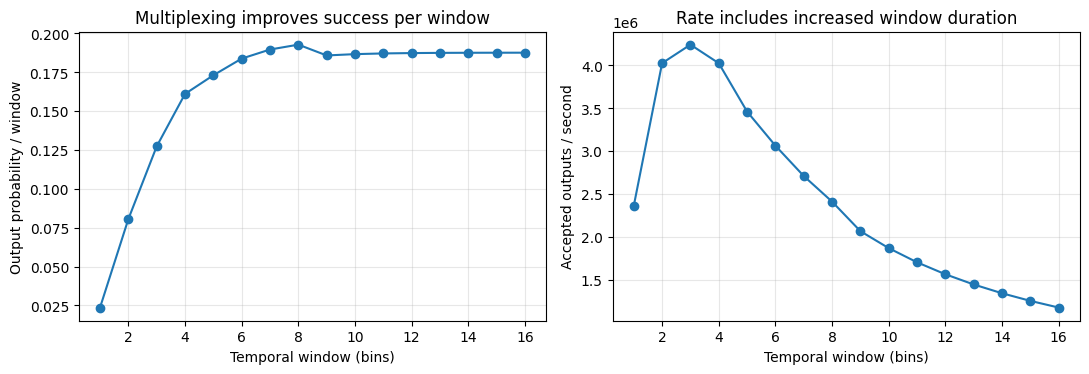

In [8]:
fig,axes=plt.subplots(1,2,figsize=(11,4))
axes[0].plot([r['bins'] for r in rows],[r['success_probability'] for r in rows],marker='o')
axes[0].set(xlabel='Temporal window (bins)',ylabel='Output probability / window',title='Multiplexing improves success per window')
axes[1].plot([r['bins'] for r in rows],[r['throughput_hz'] for r in rows],marker='o')
axes[1].set(xlabel='Temporal window (bins)',ylabel='Accepted outputs / second',title='Rate includes increased window duration')
for ax in axes: ax.grid(alpha=.3)
fig.tight_layout();fig.savefig(FIGURES/'multiplex_tradeoff.png',dpi=160);plt.show()

## Part 5 — Optical circuit primitive: a balanced beam splitter

An ideal balanced beam splitter transforms creation operators according to a unitary $U_{\rm BS}$. For one common phase convention,
$$U_{\rm BS}=\frac{1}{\sqrt2}\begin{pmatrix}1&i\\i&1\end{pmatrix}.$$
For two indistinguishable photons injected into separate input modes, bosonic interference leads to Hong–Ou–Mandel bunching and suppressed one-photon-per-port coincidence. This two-mode exercise is **not** a working fusion gate: real fusion measurements require a specified qubit encoding, interferometer, detectors, measurement outcomes, and postselection/feed-forward rules.

The next cell is optional because installing Perceval is not necessary to reproduce the analytical scheduling results. Compare with the [Perceval documentation](https://perceval.quandela.net/docs/v1.3/notebooks/Circuit_Tutorial.html).

In [9]:
# Optional physical-optics sanity check using a two-mode beam splitter.
# Install separately: python -m pip install perceval-quandela
try:
    import perceval as pcvl
    circuit = pcvl.BS()
    print('Perceval available: balanced beam splitter constructed:', circuit)
    print('Input example:', pcvl.BasicState('|1,1>'))
except ImportError:
    print('Perceval not installed; optional cell skipped. Analytical model remains runnable.')

Perceval not installed; optional cell skipped. Analytical model remains runnable.


## Part 6 — Monte Carlo simulation, overhead and convergence

Every simulation trial draws $k\times m$ initial availability flags, chooses the latest available time bin on each rail, samples delay and switch survival, then samples $f$ heralded fusion outcomes. The estimator is $\widehat P=n_{\rm out}/M$ with approximate standard error
$$\widehat\sigma=\sqrt{\widehat P(1-\widehat P)/M}.$$

The **raw source-attempt overhead** per accepted output is $C=km/P_{\rm out}$. This counts source trigger opportunities, not fabricated component cost, energy usage, or a full fault-tolerant resource budget.

In [10]:
a = Architecture(rails=3, bins=4, fusions=2)
exact = analytical_metrics(a, h)
mc = monte_carlo(a, h, shots=150_000, seed=42)

print("Analytical metrics:")
for name, value in exact.items():
    print(f"  {name:27s} {float(value):.6g}")
print("Monte Carlo estimates:")
for name, value in mc.items():
    if isinstance(value, (int, np.integer)):
        print(f"  {name:27s} {int(value)}")
    else:
        print(f"  {name:27s} {float(value):.6g}")

se_exact = np.sqrt(exact["success_probability"] *
                   (1 - exact["success_probability"]) / mc["shots"])
assert abs(mc["success_probability"] - exact["success_probability"]) < 5 * se_exact
print("Monte Carlo validated against exact probability")

Analytical metrics:
  rail_acceptance             0.863683
  success_probability         0.161066
  attempts_per_window         12
  switch_depth                2
  window_s                    4e-08
  throughput_hz               4.02665e+06
  attempts_per_output         74.5037
Monte Carlo estimates:
  success_probability         0.161327
  standard_error              0.000949738
  successes                   24199
  shots                       150000
  throughput_hz               4.03317e+06
  attempts_per_output         74.3832
  mean_selected_storage_bins  0.810531
Monte Carlo validated against exact probability


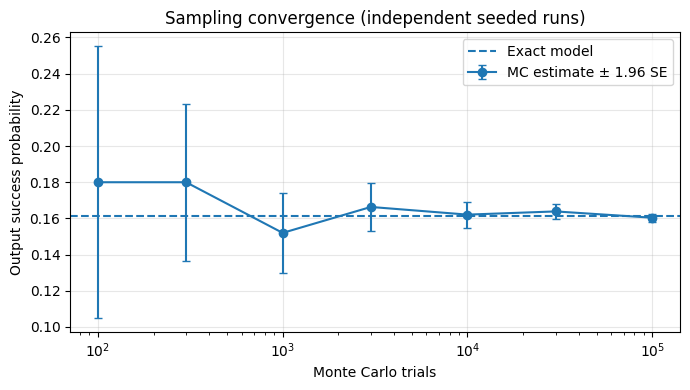

In [11]:
shots_list = np.array([100, 300, 1000, 3000, 10000, 30000, 100000])
est, se = [], []
for idx, n in enumerate(shots_list):
    result = monte_carlo(a, h, shots=int(n), seed=123 + idx)
    est.append(result["success_probability"])
    se.append(result["standard_error"])

fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(shots_list, est, yerr=1.96 * np.array(se), marker="o", capsize=3,
            label="MC estimate ± 1.96 SE")
ax.axhline(exact["success_probability"], ls="--", label="Exact model")
ax.set_xscale("log")
ax.set(xlabel="Monte Carlo trials", ylabel="Output success probability",
       title="Sampling convergence (independent seeded runs)")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURES / "monte_carlo_convergence.png", dpi=160)
plt.show()

## Part 7 — Optimization, Pareto trade-offs and hardware sensitivity

For fixed rail count $k$ and bin period $T$, the **nominal source-attempt overhead per accepted output** and the accepted rate are not independent:

$$
C_{\mathrm{output}}\,R_{\mathrm{out}}
=\frac{k m}{P_{\mathrm{out}}}\frac{P_{\mathrm{out}}}{mT}
=\frac{k}{T}.
$$

Thus minimizing $C_{\mathrm{output}}$ is algebraically equivalent to maximizing $R_{\mathrm{out}}$. A Pareto analysis of those two quantities would be degenerate. We retain $C_{\mathrm{output}}$ as a reported efficiency metric, but use **provisioned source attempts per window** $C_{\mathrm{window}}=km$ as the Pareto resource axis. That metric increases with the multiplexing window even when the accepted rate saturates or decreases.

A candidate is dominated if another requires no more source attempts **per window**, achieves no smaller accepted rate, and strictly improves at least one of these objectives. Source attempts are operational opportunities, **not** the number of physical emitters, procurement cost, or energy consumption; the switching depth is reported separately. The comparison remains restricted to the model's non-overlapping windows and fixed input parameters.

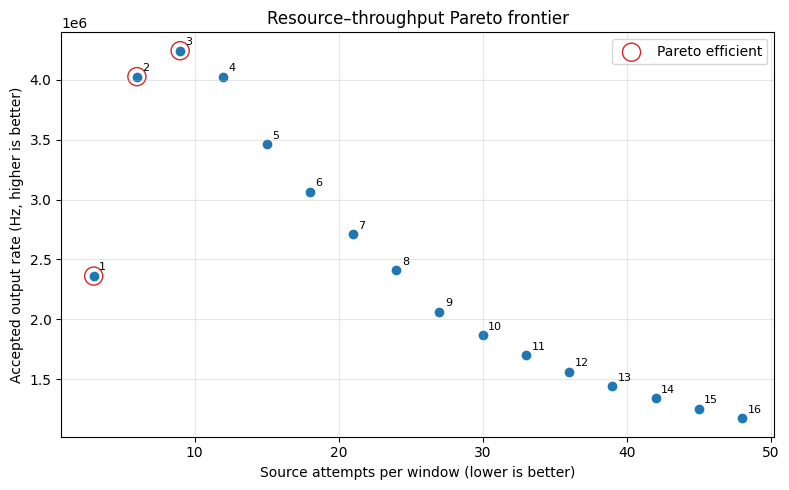

Pareto bins: [1, 2, 3]


In [12]:
front = pareto_front(rows, cost_key="attempts_per_window", benefit_key="throughput_hz")
assert [r["bins"] for r in front] == [1, 2, 3]
assert all(np.isclose(r["attempts_per_output"] * r["throughput_hz"],
                      3 / (h.period_ns * 1e-9)) for r in rows)

fig, ax = plt.subplots(figsize=(8, 5))
for r in rows:
    ax.scatter(r["attempts_per_window"], r["throughput_hz"], color="tab:blue")
    ax.annotate(str(r["bins"]),
                (r["attempts_per_window"], r["throughput_hz"]),
                xytext=(4, 4), textcoords="offset points", fontsize=8)
ax.scatter([r["attempts_per_window"] for r in front],
           [r["throughput_hz"] for r in front], facecolors="none",
           edgecolors="tab:red", s=170, label="Pareto efficient")
ax.set(xlabel="Source attempts per window (lower is better)",
       ylabel="Accepted output rate (Hz, higher is better)",
       title="Resource–throughput Pareto frontier")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURES / "pareto_frontier.png", dpi=160)
plt.show()
print("Pareto bins:", [r["bins"] for r in front])

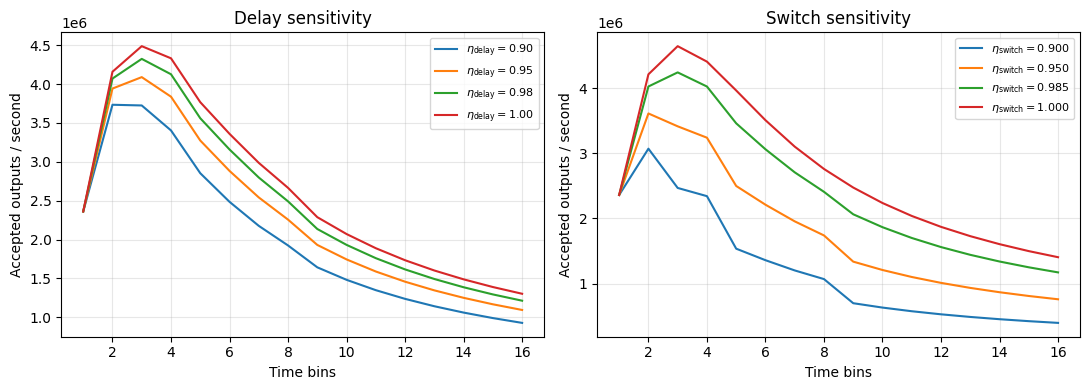

In [13]:
fig,axes=plt.subplots(1,2,figsize=(11,4))
for loss in [.90,.95,.98,1.0]:
    hw=replace(h,delay_eff_per_bin=loss)
    vals=sweep_bins(hw,bins=range(1,17))
    axes[0].plot([r['bins'] for r in vals],[r['throughput_hz'] for r in vals],label=fr'$\eta_{{\mathrm{{delay}}}}={loss:.2f}$')
for switch in [.90,.95,.985,1.0]:
    hw=replace(h,switch_eff=switch)
    vals=sweep_bins(hw,bins=range(1,17))
    axes[1].plot([r['bins'] for r in vals],[r['throughput_hz'] for r in vals],label=fr'$\eta_{{\mathrm{{switch}}}}={switch:.3f}$')
axes[0].set(title='Delay sensitivity',xlabel='Time bins',ylabel='Accepted outputs / second')
axes[1].set(title='Switch sensitivity',xlabel='Time bins',ylabel='Accepted outputs / second')
for ax in axes: ax.legend(fontsize=8);ax.grid(alpha=.3)
fig.tight_layout();fig.savefig(FIGURES/'hardware_sensitivity.png',dpi=160);plt.show()

## Part 8 — Final reproducible experiment and reporting

The final experiment scans window length $m=1,\ldots,16$ for fixed physical assumptions, and reports analytical output probability, rate, raw source-attempt overhead per accepted output, provisioned source attempts per window, and switching depth. We compare to Monte Carlo at representative settings. All choices are recorded explicitly; **no predetermined improvement** is assumed.

### Physical interpretation

- Optical losses penalize longer storage and more switching stages.
- The latest-success selection policy is model-specific; other adaptive schemes can perform differently.
- Sequential spin-assisted and multiplexed unassisted preparation need not generate the same target graph state, so the simple comparisons are **resource model illustrations**, not a demonstrated architectural advantage.
- A final fault-tolerant claim requires an explicit fusion circuit, physical error channels, decoding, and logical failure-rate studies.

The rate-maximizing window also minimizes per-output attempt overhead **by construction**; the separate rate-versus-per-window-resource frontier in Part 7 identifies the additional provisioning required to reach that optimum.

In [14]:
import csv

rows = sweep_bins(h, rails=3, fusions=2, bins=range(1, 17))
out = RESULTS / "window_sweep.csv"
with out.open("w", newline="") as handle:
    writer = csv.DictWriter(handle, fieldnames=list(rows[0].keys()))
    writer.writeheader()
    writer.writerows(rows)

opt_rate = max(rows, key=lambda row: row["throughput_hz"])
opt_overhead = min(rows, key=lambda row: row["attempts_per_output"])
opt_window_resources = min(rows, key=lambda row: row["attempts_per_window"])
final_front = pareto_front(rows, cost_key="attempts_per_window",
                          benefit_key="throughput_hz")
print("Maximum throughput:", opt_rate["bins"], "bins",
      round(opt_rate["throughput_hz"], 2), "Hz")
print("Minimum source attempts per accepted output:",
      opt_overhead["bins"], "bins", round(opt_overhead["attempts_per_output"], 2))
print("Minimum provisioned source attempts/window:",
      opt_window_resources["bins"], "bin", opt_window_resources["attempts_per_window"])
print("Rate–window-resource Pareto bins:", [row["bins"] for row in final_front])
print("Saved:", out)

Maximum throughput: 3 bins 4243481.91 Hz
Minimum source attempts per accepted output: 3 bins 70.7
Minimum provisioned source attempts/window: 1 bin 3
Rate–window-resource Pareto bins: [1, 2, 3]
Saved: results/window_sweep.csv


### Verification and interpretation

- For one bin, the switching-tree depth is zero and the acceptance formula reduces to a single opportunity per rail.
- With unit source, transmission, detector, switch, delay, and fusion efficiencies, every window succeeds.
- For lossless storage and switching, a single rail succeeds with probability $1-(1-p_0)^m$.
- Monte Carlo estimates should agree with the analytical probabilities within sampling uncertainty.

The model deliberately omits circuit-level optical fusion, feed-forward, spin–photon error channels, and experimental device calibration. The following section addresses one further limitation: finite shared optical-buffer capacity. It also changes the photon-selection policy, so any comparison between sections must account for that difference.

**References:** Bartolucci *et al.*, *Nature Communications* **14**, 912 (2023), https://doi.org/10.1038/s41467-023-36493-1; Chan *et al.*, *PRX Quantum* **6**, 020304 (2025), https://doi.org/10.1103/PRXQuantum.6.020304.

## Part 9 — Extension: finite-buffer online scheduling

### Motivation and scope

The latest-arrival model in Section 4 treats each rail independently and does not limit the number of photons that can be held at the common synchronization deadline. For a shared optical store, this assumption can overestimate feasible resource preparation: an arriving photon may have no free storage slot even though its source emitted successfully.

Here, a **finite-capacity event-driven scheduler** accepts the **first available photon** from each unsatisfied rail, provided a slot is free. Accepted photons occupy one slot until the final time bin; no replacement, release, or retry is attempted after a storage loss. The simulator explicitly counts blocked arrival events and samples storage attenuation and independent switching and fusion outcomes.

This is a separate scheduling policy from the **latest-available-photon, replace-on-arrival** selection used in Sections 1–8. Both policies can be causal: the difference is replacement and the allocation of shared storage, not access to future information. Their success probabilities should only be compared when the physical assumptions and selection policy are aligned. The finite-buffer model is a classical event-level resource surrogate; it does not simulate optical switching circuits, quantum measurement back-action, or graph-state fidelity.

In [15]:
# Illustrative component parameters; not experimentally calibrated.
RAILS = 3
BINS = 8
P_EMIT = 0.42
ETA_DELAY = 0.97
ETA_SWITCH = 0.98
FUSION = 0.50

### 9.1 Event-driven shared-buffer model

At each time bin, each rail may produce one candidate photon with probability $p$. The policy retains **the first available photon** from each unsatisfied rail if a shared storage slot is free. Stored photons remain until the deadline. For age $a=m-1-t$, optical storage survival is $\eta_d^a$, and a fusion succeeds independently with probability $h$.

**Both selection rules are causal.** The baseline latest-arrival policy can replace an older stored photon when a fresher candidate becomes available, assuming dedicated per-rail storage and free replacement. Here, the online controller instead accepts the first arrival and holds it until the deadline without replacement; all rails contend for a **shared finite buffer**. It does not use future arrival information either. The two protocols therefore differ in storage and replacement assumptions rather than causality.

Within the chosen hold-until-deadline convention, **even photons arriving in the last bin occupy a storage slot**; direct output bypass is outside this model. A capacity below the number of rails therefore precludes successful output under these specific rules.

In [16]:
def simulate_online(rails, bins, capacity, p_emit, eta_delay,
                    eta_switch, fusion, shots=20_000, seed=3):
    """First-arrival retention under a shared, hold-until-deadline buffer."""
    assert rails >= 1 and bins >= 1 and capacity >= 0 and shots > 0
    assert all(0 <= value <= 1 for value in
               (p_emit, eta_delay, eta_switch, fusion))

    rng = np.random.default_rng(seed)
    # Draw independent random arrays successively from one seeded RNG.
    # Reusing a seed across capacity alternatives gives common random numbers
    # for the underlying arrivals, losses and fusion events.
    arrivals = rng.random((shots, bins, rails)) < p_emit
    delays = rng.random((shots, rails))
    switches = rng.random((shots, rails))
    fusion_draw = rng.random(shots)

    accepted = np.zeros((shots, rails), dtype=bool)
    ages = np.zeros((shots, rails), dtype=int)
    blocked = 0
    for t in range(bins):
        for rail in range(rails):
            waiting = arrivals[:, t, rail] & ~accepted[:, rail]
            space = accepted.sum(axis=1) < capacity
            take = waiting & space
            blocked += int((waiting & ~space).sum())
            accepted[take, rail] = True
            ages[take, rail] = bins - 1 - t

    survival = ((delays < eta_delay**ages) &
                (switches < eta_switch))
    ready = np.all(accepted & survival, axis=1)
    success = ready & (fusion_draw < fusion)
    return {
        "P": float(success.mean()),
        "count": int(success.sum()),
        "blocked": blocked,
        "ready": float(ready.mean()),
        "mean_storage_bins": float(ages[accepted].mean()) if accepted.any() else np.nan,
    }


for capacity in (1, 2, 3):
    result = simulate_online(RAILS, BINS, capacity, P_EMIT, ETA_DELAY,
                             ETA_SWITCH, FUSION, seed=10)
    print(f"Capacity {capacity}: {result}")

Capacity 1: {'P': 0.0, 'count': 0, 'blocked': 124895, 'ready': 0.0, 'mean_storage_bins': 6.75675}
Capacity 2: {'P': 0.0, 'count': 0, 'blocked': 54751, 'ready': 0.0, 'mean_storage_bins': 6.362315578894724}
Capacity 3: {'P': 0.27115, 'count': 5423, 'blocked': 0, 'ready': 0.5403, 'mean_storage_bins': 5.725560416913019}


### 9.2 Analytical baseline: unlimited buffer, earliest-arrival policy
If capacity is at least the number of rails, each rail behaves independently. For $m$ bins, the probability of picking the **first** photon at bin $t$ and then retaining it through storage is
$$
r_m=\eta_{\mathrm{sw}}\sum_{t=0}^{m-1}(1-p)^t p\,\eta_d^{m-1-t}.
$$
For $k$ independent rails and one independent fusion success flag, $P=r_m^k h$. This is a formula specific to the first-arrival policy; it is distinct from the latest-arrival formula in Section 4.


In [17]:
def exact_online_unlimited(rails, bins, p, delay, switch, fusion):
    rail = switch * sum((1 - p)**t * p * delay**(bins - 1 - t)
                        for t in range(bins))
    return rail**rails * fusion


online_exact = exact_online_unlimited(RAILS, BINS, P_EMIT, ETA_DELAY,
                                      ETA_SWITCH, FUSION)
online_mc = simulate_online(RAILS, BINS, RAILS, P_EMIT, ETA_DELAY,
                            ETA_SWITCH, FUSION, shots=150_000, seed=23)
online_se = np.sqrt(online_exact * (1 - online_exact) / 150_000)
print(f'Exact {online_exact:.6f}; Monte Carlo {online_mc["P"]:.6f}; '
      f'theoretical SE {online_se:.6f}')
assert abs(online_mc["P"] - online_exact) < 5 * online_se

Exact 0.269314; Monte Carlo 0.268073; theoretical SE 0.001145


### 9.3 Buffer-capacity sweep and accepted output rate
All designs use the same window length $m\Delta t$. For a per-bin period $\Delta t$, throughput is $P/(m\Delta t)$. Capacity is a **resource constraint**, not a made-up financial cost.


Because this policy retains every selected photon through the output deadline, capacities $c<k$ produce zero accepted output. The accompanying **blocked-arrival count** nevertheless differentiates the sub-capacity designs. This restriction is model-specific and excludes direct deadline-bin bypass.

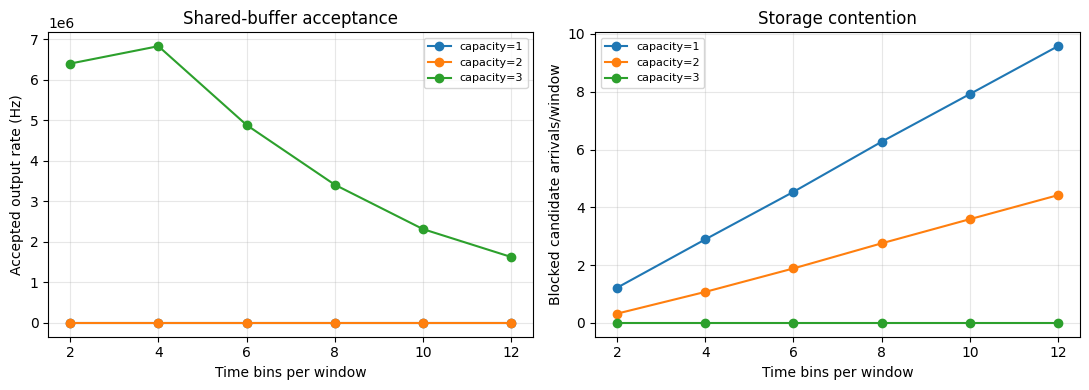

In [18]:
online_rows = []
PERIOD_NS = 10
SHOTS_SWEEP = 20_000
for bins in (2, 4, 6, 8, 10, 12):
    for capacity in (1, 2, 3):
        # Same seed for each capacity at a given window: common random numbers.
        result = simulate_online(RAILS, bins, capacity, P_EMIT, ETA_DELAY,
                                 ETA_SWITCH, FUSION, shots=SHOTS_SWEEP,
                                 seed=9 + bins)
        online_rows.append({
            "bins": bins,
            "capacity": capacity,
            "accepted_probability": result["P"],
            "throughput_hz": result["P"] / (bins * PERIOD_NS * 1e-9),
            "blocked_per_window": result["blocked"] / SHOTS_SWEEP,
        })

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for capacity in (1, 2, 3):
    subset = [row for row in online_rows if row["capacity"] == capacity]
    bins_axis = [row["bins"] for row in subset]
    axes[0].plot(bins_axis, [row["throughput_hz"] for row in subset],
                 marker="o", label=f"capacity={capacity}")
    axes[1].plot(bins_axis, [row["blocked_per_window"] for row in subset],
                 marker="o", label=f"capacity={capacity}")
axes[0].set(xlabel="Time bins per window", ylabel="Accepted output rate (Hz)",
            title="Shared-buffer acceptance")
axes[1].set(xlabel="Time bins per window", ylabel="Blocked candidate arrivals/window",
            title="Storage contention")
for ax in axes:
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURES / "finite_buffer_scheduling.png", dpi=160)
plt.show()

### 9.4 Limiting cases and validation
With fewer storage slots than required rails, no accepted output is possible under our *no-replacement and hold-until-output* assumptions. With $p=1$, full capacity and no loss, acceptance must equal the fusion probability. For reproducible seeded Monte Carlo, all code is deterministic up to floating-point precision.


Capacities greater than $k$ are permitted but provide no additional benefit because at most one photon per rail can be retained. This can be checked using common random numbers.

In [19]:
subcapacity = simulate_online(3, 5, 2, 1, 1, 1, 1, shots=1000)
assert subcapacity["P"] == 0
full_capacity = simulate_online(3, 5, 3, 1, 1, 1, 1, shots=1000)
assert full_capacity["P"] == 1
zero_emission = simulate_online(3, 5, 3, 0, 1, 1, 1, shots=1000)
assert zero_emission["P"] == 0
assert np.isclose(exact_online_unlimited(3, 1, 0.5, 0.97, 0.98, 0.5),
                  (0.5 * 0.98)**3 * 0.5)

bounded = simulate_online(3, 5, 3, 0.5, 0.97, 0.98, 0.5,
                          shots=5000, seed=47)
extra = simulate_online(3, 5, 4, 0.5, 0.97, 0.98, 0.5,
                        shots=5000, seed=47)
assert bounded == extra
print("All extension checks passed (including capacity > rails).")

All extension checks passed (including capacity > rails).


### 9.5 Controlled comparison of selection policies

The main and extended models use different *causal* selection policies. To isolate the **policy difference**, set both switch efficiencies to one, use the same per-bin source availability and storage transmission, and require one fusion success flag. In the absence of storage loss, first-arrival and latest-arrival selection give the same success probability. With storage attenuation, latest-arrival selection is at least as successful in this simplified independent-rail setting because the selected photon is no older.

This comparison assumes **unlimited storage capacity** for the first-arrival model; it does not benchmark physical switching hardware.

In [20]:
# Match input availability, storage attenuation, switching, and heralding.
matched_hardware = Hardware(
    source_prob=P_EMIT, transmission=1.0, detector_eff=1.0,
    switch_eff=1.0, delay_eff_per_bin=ETA_DELAY,
    fusion_prob=FUSION, period_ns=PERIOD_NS,
)
matched_architecture = Architecture(rails=RAILS, bins=BINS, fusions=1)
latest_policy = analytical_metrics(matched_architecture, matched_hardware)["success_probability"]
first_policy = exact_online_unlimited(RAILS, BINS, P_EMIT, ETA_DELAY, 1.0, FUSION)
print(f"Latest-arrival selection: {latest_policy:.6f}")
print(f"First-arrival selection:  {first_policy:.6f}")
assert latest_policy >= first_policy - 1e-12

matched_lossless = replace(matched_hardware, delay_eff_per_bin=1.0)
assert np.isclose(
    analytical_metrics(matched_architecture, matched_lossless)["success_probability"],
    exact_online_unlimited(RAILS, BINS, P_EMIT, 1.0, 1.0, FUSION),
)
print("Matched-assumption policy checks passed.")

Latest-arrival selection: 0.429476
First-arrival selection:  0.286141
Matched-assumption policy checks passed.


### Reproducibility checks

The checks below cover both models in this single-file distribution. They test probability limits and compare the corresponding analytical and stochastic estimates. Passing them verifies these model-specific relations, not agreement with measured optical hardware.

In [21]:
ideal_h = Hardware(source_prob=1.0, transmission=1.0, detector_eff=1.0,
                   switch_eff=1.0, delay_eff_per_bin=1.0, fusion_prob=1.0)
assert np.isclose(analytical_metrics(Architecture(rails=3, bins=5, fusions=2), ideal_h)['success_probability'], 1.0)
assert switch_depth(1) == 0
single_bin_h = Hardware(source_prob=0.5, transmission=1.0, detector_eff=1.0,
                        switch_eff=0.9, delay_eff_per_bin=0.7, fusion_prob=1.0)
assert np.isclose(per_rail_acceptance(Architecture(rails=1, bins=1, fusions=0), single_bin_h), 0.5)
assert simulate_online(3, 5, 2, 1.0, 1.0, 1.0, 1.0, shots=1000)['P'] == 0.0
assert simulate_online(3, 5, 3, 1.0, 1.0, 1.0, 1.0, shots=1000)['P'] == 1.0
assert np.isclose(online_mc['P'], online_exact, atol=5*online_se)
print('All notebook-level analytical and limiting-case checks passed.')

All notebook-level analytical and limiting-case checks passed.


### 9.6 Interpretation and remaining scope

A finite shared buffer introduces a resource constraint absent from the independent-rail model. Blocking events, storage ages, and accepted output rates can now be studied under an explicit **first-arrival, hold-until-deadline** policy. The unlimited-buffer analytical expression provides an independent reference for the corresponding stochastic simulation.

Capacity below the number of required rails necessarily yields zero accepted outputs **for this specific hold-until-deadline policy**, since all required photons must be stored simultaneously. It is not a general limit on multiplexed photonic architectures.

Both policies can be implemented causally, although doing so may require different optical control resources. The two policies studied here are distinct. The original model uses latest-arrival selection, while the finite-buffer model uses earliest-arrival selection and one switch transmission factor per stored photon. The latter does not include a multiplexing-dependent switch-tree depth. Consequently, a difference in output rate is not automatically attributable to buffer capacity alone.

Neither model includes circuit-level fusion outcomes, spin–photon dynamics, spectral distinguishability, buffer write/read noise, feed-forward latency, physical switch-routing conflicts, or cluster-state fidelity. The parameters are illustrative rather than experimentally calibrated.

The Part 7 resource–throughput Pareto frontier uses provisioned source attempts *per window*, while per-accepted-output attempt overhead remains a useful but rate-reciprocal statistic at fixed $k$ and $T$. Neither metric alone quantifies physical emitter count or actual power consumption.